In [ ]:
import pandas as pd

df = pd.read_csv('https://raw.githubusercontent.com/jorgermzg15/data-files/refs/heads/main/CarPrice_dataset.csv')

print("Muestra del dataset:")
df.head()

Muestra del dataset:


,CarName,carbody,fueltype,enginetype,cylindernumber,doornumber,symboling,wheelbase,carlength,carwidth,...,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,alfa-romero giulia,convertible,gas,dohc,4,2,3,88.6,168.8,64.1,...,2548,130,3.47,2.68,9.0,111,5000,21,27,13495.0
1,alfa-romero stelvio,convertible,gas,dohc,4,2,3,88.6,168.8,64.1,...,2548,130,3.47,2.68,9.0,111,5000,21,27,16500.0
2,alfa-romero Quadrifoglio,hatchback,gas,ohcv,6,2,1,94.5,171.2,65.5,...,2823,152,2.68,3.47,9.0,154,5000,19,26,16500.0
3,audi 100 ls,sedan,gas,ohc,4,4,2,99.8,176.6,66.2,...,2337,109,3.19,3.40,10.0,102,5500,24,30,13950.0
4,audi 100ls,sedan,gas,ohc,5,4,2,99.4,176.6,66.4,...,2824,136,3.19,3.40,8.0,115,5500,18,22,17450.0


enginesize          0.675420
curbweight          0.235578
carwidth            0.019698
compressionratio    0.016401
peakrpm             0.015779
horsepower          0.011656
stroke              0.006883
carlength           0.005857
symboling           0.004067
citympg             0.003412
wheelbase           0.002212
highwaympg          0.001147
boreratio           0.000769
carheight           0.000670
doornumber          0.000377
cylindernumber      0.000073
dtype: float64


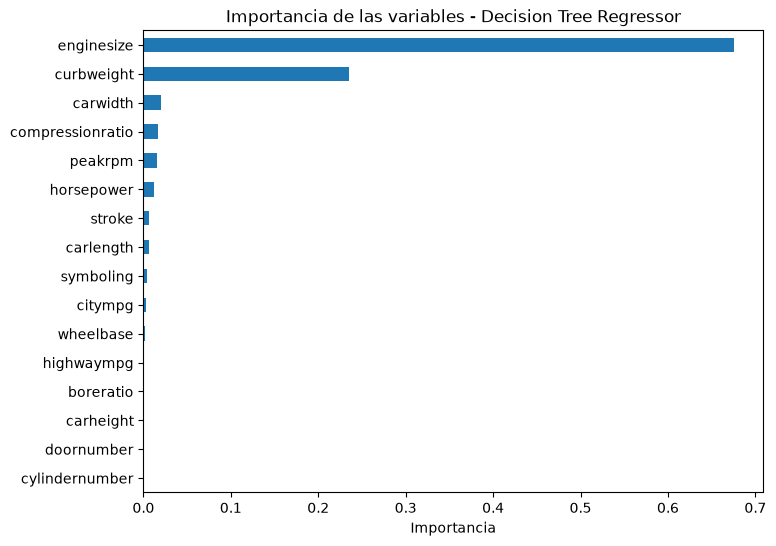

In [ ]:


import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

df_num = df.select_dtypes(include='number')
X = df_num.drop(columns='price')
y = df_num['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)


modelo = DecisionTreeRegressor(random_state=0)
modelo.fit(X_train, y_train)

importancias = pd.Series(modelo.feature_importances_, index=X.columns).sort_values()
print(importancias.sort_values(ascending=False))

# Grafica
importancias.plot(kind='barh', figsize=(8, 6))
plt.title('Importancia de las variables - Decision Tree Regressor')
plt.xlabel('Importancia')
plt.show()

In [14]:
#preg 14
from sklearn.metrics import r2_score
X = df[['enginesize', 'curbweight']]
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

modelo2 = DecisionTreeRegressor(random_state=0)
modelo2.fit(X_train, y_train)

print("X_train.shape =", X_train.shape)
print("X_test.shape =", X_test.shape)
print("y_train.shape =", y_train.shape)
print("y_test.shape =", y_test.shape)



X_train.shape = (164, 2)
X_test.shape = (41, 2)
y_train.shape = (164,)
y_test.shape = (41,)


In [18]:
#preg 15
r2_train = r2_score(y_train, modelo2.predict(X_train)) * 100
r2_test = r2_score(y_test, modelo2.predict(X_test)) * 100
diferencia = r2_train - r2_test

print("R2_train =", round(r2_train, 2))
print("R2_test =", round(r2_test, 2))
print("Diferencia =", round(diferencia, 2))


R2_train = 99.83
R2_test = 88.86
Diferencia = 10.97


In [19]:
#prerg 16
overfitting = diferencia > 10
print("Diferencia =", round(diferencia, 2))
print("¿Overfitting?", overfitting)

Diferencia = 10.97
¿Overfitting? True


In [20]:
#preg 17
import numpy as np
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error

pred_train = modelo2.predict(X_train)
pred_test = modelo2.predict(X_test)

mape_train = mean_absolute_percentage_error(y_train, pred_train) * 100
mape_test = mean_absolute_percentage_error(y_test, pred_test) * 100
rmse_train = np.sqrt(mean_squared_error(y_train, pred_train))
rmse_test = np.sqrt(mean_squared_error(y_test, pred_test))

print("MAPE_train =", round(mape_train, 2))
print("MAPE_test =", round(mape_test, 2))
print("RMSE_train =", round(rmse_train, 2))
print("RMSE_test =", round(rmse_test, 2))


MAPE_train = 0.77
MAPE_test = 18.51
RMSE_train = 322.88
RMSE_test = 2936.83


las predicciones se equivocan en promedio un 18.51% del precio real
el modelo se equivoca alrededor de 2,937 dólares.

# Parte 2

In [22]:
import pandas as pd

url = "https://raw.githubusercontent.com/jorgermzg15/data-files/refs/heads/main/phone_classification.csv"
df = pd.read_csv(url)
df.head()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,px_height,px_width,ram,talk_time,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,20,756,2549,19,0,1,Mid_Low
1,1021,1,0.5,1,0,1,53,0.7,136,3,905,1988,2631,7,1,0,Mid
2,563,1,0.5,1,2,1,41,0.9,145,5,1263,1716,2603,9,1,0,Mid
3,615,1,2.5,0,0,0,10,0.8,131,6,1216,1786,2769,11,0,0,Mid
4,1821,1,1.2,0,13,1,44,0.6,141,2,1208,1212,1411,15,1,0,Mid_Low


In [24]:
import plotly.express as px

conteo = df['price_range'].value_counts().reset_index()
conteo.columns = ['price_range', 'cantidad']

# Gráfico de barras
fig = px.bar(conteo, x='price_range', y='cantidad',
             text='cantidad',
             category_orders={'price_range': ['Low', 'Mid_Low', 'Mid', 'High']},
             title='Cantidad de observaciones por price_range')
fig.show()

In [27]:
#preg 20
df_corr = df.copy()
df_corr['price_range'] = df_corr['price_range'].map({'Low': 0, 'Mid_Low': 1, 'Mid': 2, 'High': 3})

correlaciones = df_corr.corr()['price_range'].drop('price_range')
print(correlaciones.sort_values(ascending=False))

ram              0.921647
battery_power    0.206876
px_width         0.171549
px_height        0.156043
int_memory       0.047408
blue             0.031410
fc               0.029378
talk_time        0.025332
wifi             0.021363
dual_sim         0.016497
four_g           0.015491
m_dep            0.004895
n_cores          0.002594
clock_speed     -0.002126
touch_screen    -0.029865
mobile_wt       -0.030850
Name: price_range, dtype: float64


In [28]:
#preg 21
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFECV

X = df.drop(columns='price_range')
y = df['price_range']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

scaler = StandardScaler()
scaler.fit(X_train)                       # se ajusta solo con train
X_train_sc = scaler.transform(X_train)
X_test_sc = scaler.transform(X_test)

modelo_log = LogisticRegression(random_state=0, max_iter=500)
rfecv = RFECV(estimator=modelo_log, cv=5)
rfecv.fit(X_train_sc, y_train)

print("Número óptimo de variables:", rfecv.n_features_)
print("Variables seleccionadas:", list(X.columns[rfecv.support_]))

Número óptimo de variables: 5
Variables seleccionadas: ['battery_power', 'mobile_wt', 'px_height', 'px_width', 'ram']


In [29]:
#preg 23

variables = list(X.columns[rfecv.support_])
matriz_sel = df[variables].corr().round(2)

fig = px.imshow(matriz_sel, text_auto=True, color_continuous_scale='RdBu_r',
                zmin=-1, zmax=1,
                title='Correlación entre variables seleccionadas por RFECV')
fig.show()

# Comprobación automática
import numpy as np
mask = np.triu(np.ones(matriz_sel.shape, dtype=bool), k=1)   # solo pares distintos
print("¿Multicolinealidad?", (matriz_sel.abs().where(mask) > 0.8).any().any())

¿Multicolinealidad? False


In [30]:
#preg 24
from sklearn.metrics import accuracy_score

variables = list(X.columns[rfecv.support_])

# Mismo split; escalamiento solo con las variables seleccionadas
X_train_sel = X_train[variables]
X_test_sel = X_test[variables]

scaler_sel = StandardScaler()
scaler_sel.fit(X_train_sel)
X_train_sel_sc = scaler_sel.transform(X_train_sel)
X_test_sel_sc = scaler_sel.transform(X_test_sel)

log_reg = LogisticRegression(random_state=0, max_iter=500)
log_reg.fit(X_train_sel_sc, y_train)

acc_train = accuracy_score(y_train, log_reg.predict(X_train_sel_sc))
acc_test = accuracy_score(y_test, log_reg.predict(X_test_sel_sc))

print("Accuracy_train =", round(acc_train, 4))
print("Accuracy_test =", round(acc_test, 4))
print("Diferencia =", round(acc_train - acc_test, 4))

Accuracy_train = 0.9723
Accuracy_test = 0.9676
Diferencia = 0.0047


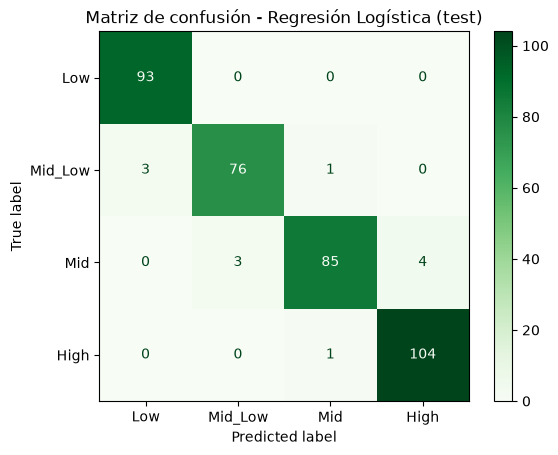

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

orden = ['Low', 'Mid_Low', 'Mid', 'High']

y_pred_test = log_reg.predict(X_test_sel_sc)
cm = confusion_matrix(y_test, y_pred_test, labels=orden)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=orden)
disp.plot(cmap='Greens')
plt.title('Matriz de confusión - Regresión Logística (test)')
plt.show()